# 13-gauss-s — Lượt S: học lại trên ảnh được giữ, dừng theo det

**Câu hỏi**: lượt S học gì trên các ảnh được giữ, dừng ở bước nào và vì sao, và việc dừng sớm đổi gì cho lớp cũ và lớp mới so với lượt F chạy đủ 1000 bước (Hình 2 của paper trên GC10)? (D14, D23, Q07.01; Q07.03 nhìn trước một phần; QD24, sửa 2026-11-05)

### Nguồn gốc

Mẫu cell 0 (`lab/README.vi.md` §11): in commit và trạng thái dirty, rồi đặt `XLA_FLAGS` ở chế độ GPU tất định trước mọi lần import jax.

In [1]:
# cell 0: provenance (run first)
import os, subprocess, sys
from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / "main.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT); sys.path[:0] = [str(ROOT), str(ROOT / "lab")]
import replay; os.environ["XLA_FLAGS"] = replay._xla_flags()   # GPU deterministic mode before any jax import
git = lambda *a: subprocess.run(["git", *a], capture_output=True, text=True).stdout.strip()
print("commit", git("rev-parse", "--short", "HEAD"),
      "| code dirty", bool(git("status", "--porcelain", "--", ".", ":(exclude)runs", ":(exclude)notes",
                               ":(exclude)lab/*.ipynb", ":(exclude)lab/*.md")),
      "| XLA_FLAGS", os.environ["XLA_FLAGS"])

commit 935647a | code dirty False | XLA_FLAGS --xla_gpu_deterministic_ops=true


- **Kết quả**: commit `935647a`, code dirty False, XLA_FLAGS `--xla_gpu_deterministic_ops=true`.

## 1. Kiểm

### 1.1 Chạy lại bước 13 ở r0 s4

Chạy lại bước 13 của `gc10_v2_ft_r0_s4` từ ảnh chụp 12 bằng `replay.rerun`, rồi so khoá `params1` (μ và Σ của 10 khe) với ảnh chụp 13. Đây là số thực, nên cho phép lệch tới 1e-6 × max|giá trị|. Ba việc kèm theo:
- in dòng log mà luật dừng in ra lúc dừng (có `early_stop_flag`);
- so 5 khe cũ của `params1` với `params0` từng bit;
- đọc số ảnh đầu vào (`keep` của ảnh chụp 12) và `S1_estop_S` trong `metrics.json`.

Đã thấy trước: bước dừng 526 (`metrics.json`; `07` §3.1); det mới 0.5248 lúc dừng và ‖μ_S‖ 0.089–0.100 (`nb-v1` cell 8).

Dự đoán [SUY LUẬN]:
- `rerun` OK 1/1 khoá, max|diff| = 0: SVI chạy ở chế độ GPU tất định, và bước 11 đã trùng từng bit dù driver đổi;
- đúng một dòng log có `early_stop_flag`, ở bước 526, `cov` khoảng 0.525;
- đầu vào 689 ảnh;
- 5 khe cũ trùng `params0` từng bit. Ảnh cũ lọt qua bộ lọc vẫn mang id cụm (nhãn khe mới), nên khe cũ không nhận gradient;
- khe mới rời điểm khởi tạo tối đa 0.0172–0.0177 ở μ. Đó là 95–98% của Σ lr tới 525 cập nhật (0.01806), giống tỷ lệ của lượt F (`11` §1.1). Ở Σ là khoảng 0.023, vì ở lượt F, Σ đi xa gấp khoảng 1.3 lần μ.

In [2]:
# 1.1 rerun step 13 (pass S: SVI on the kept pool images from params0, early stop on det) and compare with snap/13.pkl;
#     the stop line of the log; old slots vs params0; input size and the stop step in metrics.json
import io, contextlib, json, time
import numpy as np

RUN = "gc10_v2_ft_r0_s4"
buf, t0 = io.StringIO(), time.time()
with contextlib.redirect_stdout(buf):
    out, ok = replay.rerun(RUN, "13")
log = buf.getvalue()
print("\n".join(l for l in log.splitlines() if l.startswith(("rerun", "  OK", "  DIFF"))))
stop_lines = [l for l in log.splitlines() if "early_stop_flag" in l]
print(f"time {time.time() - t0:.0f} s | log lines with early_stop_flag: {len(stop_lines)}")
for l in stop_lines:
    print("  " + l)

b = replay.snapshots(RUN)
p0, p1 = b["06"]["out"]["params0"], out["params1"]
m = json.loads((replay._run_dir(RUN) / "metrics.json").read_text())
print("input: kept images", int(np.asarray(b["12"]["out"]["keep"]).sum()), "| S1_estop_S in metrics.json:", m["S1_estop_S"])
for k in ("class_means", "class_covs"):
    print(f"{k}: old slots 0-4 bit-identical to params0: {np.array_equal(p1[k][:5], p0[k][:5])} | "
          f"new slots 5-9 max|change from init| {np.abs(p1[k][5:] - p0[k][5:]).max():.4f}")

/home/rito/miniforge3/envs/vbcgcd/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
 53%|█████▎    | 526/1000 [00:32<00:29, 16.29it/s]

rerun step 13 of gc10_v2_ft_r0_s4 | device gpu | GPU now NVIDIA GeForce RTX 4060 Laptop GPU, 621.01 | GPU of the run NVIDIA GeForce RTX 4060 Laptop GPU, 617.42 | driver differs: float outputs may move in the last bits
  OK   params1      dict                   max|diff| 0
rerun step 13: OK (1/1 keys)
time 45 s | log lines with early_stop_flag: 1
  Step 526: loss = 91610.1641, train_acc = 638/689, 92.60%,  test_acc = 122/214, 57.01%, last_cov = 0.37068694829940796, cov = 0.5247918963432312, early_stop_flag = False
input: kept images 689 | S1_estop_S in metrics.json: 526
class_means: old slots 0-4 bit-identical to params0: True | new slots 5-9 max|change from init| 0.0177
class_covs: old slots 0-4 bit-identical to params0: True | new slots 5-9 max|change from init| 0.0238


- **Kết quả**:
  - `rerun` bước 13 ở r0 s4: OK 1/1 khoá, max|diff| = 0, dù driver GPU đổi (617.42 → 621.01). SVI chạy 526 bước trong 33 s; cả cell 43 s.
  - Đúng một dòng log có `early_stop_flag`:
    - `Step 526: ... train_acc = 638/689 ..., test_acc = 122/214, 57.01%, last_cov = 0.3707, cov = 0.5248, early_stop_flag = False`;
    - `S1_estop_S` trong `metrics.json` cũng là 526;
    - đầu vào là 689 ảnh được giữ.
  - 5 khe cũ của `params1` trùng `params0` từng bit, cả μ lẫn Σ.
  - Khe mới rời điểm khởi tạo tối đa 0.0177 ở μ và 0.0238 ở Σ.
- **Ý nghĩa**:
  - Đúng như dự đoán ở cả năm ý. Lượt S tái lập từng bit; khe cũ không đổi; μ đi 0.0177, tức 98% của Σ lr tới 525 cập nhật (0.01806).
  - Dòng log in `early_stop_flag = False` vì nó được in sau khi quay lui:
    - ở bước 526, tham số sau 526 cập nhật có det mới dưới ngưỡng 0.5242, nên luật dừng;
    - tham số được trả về trạng thái sau 525 cập nhật, có det 0.5248, vừa trên ngưỡng. Cờ tính lại trên trạng thái này là False.
    - Vậy `params1` luôn dừng ngay trên ngưỡng.
  - `test_acc` 122/214 = 57.01% chính là S1_New của run. `train_acc` 638/689 (92.6%) là mức bộ phân lớp cuối trùng id cụm trên tập học.

## 2. Ngân sách bước của lượt S

### 2.1 Kích thước khe mới so với ngân sách, qua 15 ảnh chụp

Dựng lại lịch learning rate bằng `optax`, đúng như `run_inference`: tăng tuyến tính 4e-6 → 4e-5 trong 100 bước, rồi giảm ×0.85 mỗi 500 bước. Cập nhật thứ t dùng lr(t).

**Cách làm**:
- Lượt S dừng ở bước s (`S1_estop_S`) và giữ tham số sau s − 1 cập nhật, nên phần ngân sách của nó là Σ_{t < s−1} lr(t) / Σ_{t < 1000} lr(t).
- Với 5 khe mới ở `params1` và `params_f`, đo bốn đại lượng: max|μ|, ‖μ‖ trung bình, ‖Σ − I‖_F trung bình, det trung bình.
- Lấy tỷ lệ lượt S / lượt F của từng đại lượng, so với phần ngân sách.

Dự đoán [SUY LUẬN]:
- tổng lr của 1000 bước là 0.0334; phần ngân sách là r0 0.54–0.64, r1 0.48–0.56, r2 0.49–0.52;
- tỷ lệ max|μ| gần bằng phần ngân sách (lệch dưới 0.03), vì ở cả hai lượt toạ độ lớn nhất đi gần hết ngân sách;
- tỷ lệ ‖μ‖ và ‖Σ − I‖_F lớn hơn phần ngân sách ở 15/15 ảnh chụp (r0 s4: ‖μ‖ khoảng 0.62, `nb-v1`), vì ở nửa sau các cập nhật đổi dấu nhiều hơn;
- det trung bình của khe mới ở `params1` nằm ngay trên ngưỡng S của FT seed đó: khoảng 0.52 ở r0, 0.59–0.60 ở r1 và r2.

In [3]:
# 2.1 step budget of pass S over the 15 snapshots: share of the summed learning rate used up to the stop (schedule rebuilt
#     with optax as in mngmm.run_inference), against the size of the novel slots in params1 (pass S) and params_f (pass F)
import optax
import pandas as pd
lr0 = replay.snapshots(RUN)["04"]["meta"]["args"]["lr"]
sched = optax.join_schedules([optax.linear_schedule(lr0, lr0 * 10, 100), optax.exponential_decay(lr0 * 10, 500, 0.85)], [100])
lrs = np.array([float(sched(t)) for t in range(1000)])               # learning rate of update t (0-based)
print(f"lr {lr0} | sum of 1000 learning rates {lrs.sum():.5f}")

def slot_size(p):
    """Size of the 5 novel slots (5-9): max|mu|, mean ||mu||, mean ||Sigma - I||_F, mean det, float64."""
    mu, S = np.asarray(p["class_means"][5:], np.float64), np.asarray(p["class_covs"][5:], np.float64)
    E = S - np.eye(S.shape[-1])
    return np.abs(mu).max(), np.linalg.norm(mu, axis=1).mean(), np.linalg.norm(E, axis=(1, 2)).mean(), np.linalg.det(S).mean()

RUNS = [f"gc10_v2_ft_r{r}_s{s}" for r in range(3) for s in range(5)]
rows21 = []
for run in RUNS:
    bl = replay.snapshots(run)
    stop = json.loads((replay._run_dir(run) / "metrics.json").read_text())["S1_estop_S"]
    F, Sv = slot_size(bl["11"]["out"]["params_f"]), slot_size(bl["13"]["out"]["params1"])
    rows21.append(dict(snap=run.replace("gc10_v2_ft_", ""), stop=stop, budget=lrs[:stop - 1].sum() / lrs.sum(),
                       max_mu_S=Sv[0], max_mu_ratio=Sv[0] / F[0], norm_mu_ratio=Sv[1] / F[1], froE_ratio=Sv[2] / F[2],
                       det_S=Sv[3], det_F=F[3]))
T21 = pd.DataFrame(rows21).set_index("snap")
print(T21.round(4).to_string())
for c in ("max_mu_ratio", "norm_mu_ratio", "froE_ratio"):
    d = T21[c] - T21["budget"]
    print(f"{c} - budget: min {d.min():+.3f}, max {d.max():+.3f}, above budget in {int((d > 0).sum())}/15")

lr 4e-06 | sum of 1000 learning rates 0.03340
       stop  budget  max_mu_S  max_mu_ratio  norm_mu_ratio  froE_ratio   det_S   det_F
snap                                                                                  
r0_s0   619  0.6364    0.0207        0.6396         0.7018      0.6855  0.5246  0.2779
r0_s1   620  0.6374    0.0208        0.6392         0.7079      0.6869  0.5241  0.2820
r0_s2   593  0.6099    0.0200        0.6138         0.6813      0.6677  0.5266  0.2631
r0_s3   531  0.5460    0.0178        0.5517         0.6159      0.6015  0.5269  0.2245
r0_s4   526  0.5408    0.0177        0.5469         0.6157      0.5991  0.5248  0.2304
r1_s0   543  0.5585    0.0182        0.5613         0.6217      0.6199  0.5932  0.2838
r1_s1   549  0.5647    0.0185        0.5741         0.6325      0.6243  0.5904  0.2901
r1_s2   534  0.5491    0.0180        0.5534         0.6138      0.6120  0.5957  0.2888
r1_s3   486  0.4988    0.0163        0.5030         0.5675      0.5595  0.5932  0.24

- **Kết quả**:
  - Tổng lr của 1000 bước là 0.03340.
  - Phần ngân sách mà lượt S dùng: r0 0.541–0.637, r1 0.480–0.565, r2 0.487–0.521.
  - Tỷ lệ lượt S / lượt F, trừ đi phần ngân sách:
    - max|μ|: +0.002 đến +0.010;
    - ‖μ‖: +0.063 đến +0.075;
    - ‖Σ − I‖_F: +0.049 đến +0.067;
    - cả ba dương ở 15/15 ảnh chụp.
  - max|μ| của khe mới ở `params1`: 0.0157–0.0208.
  - det trung bình của khe mới:
    - ở `params1`: r0 0.524–0.527, r1 0.590–0.596, r2 0.599–0.604;
    - ở `params_f`: 0.22–0.29.
- **Ý nghĩa**:
  - Đúng như dự đoán ở cả bốn ý. Toạ độ lớn nhất của μ đi đúng theo ngân sách, sai lệch không quá 1 điểm phần trăm. Vậy D23 giữ nguyên ở lượt S: kích thước khe mới được quyết định bởi số bước mà luật dừng cho phép, không bởi dữ liệu.
  - Chuẩn ‖μ‖ và ‖Σ − I‖_F hơn phần ngân sách 5–8 điểm. Nửa đầu ngân sách đẩy được nhiều hơn nửa sau.
  - det cuối của lượt S luôn nằm ngay trên ngưỡng S của FT seed đó (0.524 / 0.59 / 0.60), đúng như quay lui một bước ở 1.1.
  - [SUY LUẬN] Trong một FT seed, bước dừng đi cùng chiều với det của lượt F ở bước 1000:
    - r0: det 0.278, 0.282, 0.263, 0.225, 0.230 với bước dừng 619, 620, 593, 531, 526;
    - r1 và r2 gần như cùng thứ tự.
    
    det rơi chậm ở lượt F thì lượt S cũng dừng muộn. §4 kiểm điều này bằng độ tản cụm.

## 3. Quỹ đạo ở r0 s4

### 3.1 Ghi quỹ đạo của lượt F và lượt S; det theo từng bước (Q07.01)

`run_inference` gọi `calculate_metrics_on_covariances` ở đầu mỗi bước SVI với tham số hiện tại, tức tham số sau t cập nhật ở bước t. Bọc hàm này ở mức class `MNGMMClassifier` để ghi 5 khe mới và hai det trung bình ở mỗi lần gọi. Bọc ở mức class vì `stop_default` gỡ mọi phép thay hàm ở mức đối tượng. Hàm gốc được trả lại trong `finally`.

Chạy lại bước 11 (lượt F) và bước 13 (lượt S) bằng `replay.rerun`. Cả hai vẫn phải trùng ảnh chụp, để chứng tỏ bộ ghi không đổi kết quả.

Quỹ đạo dựng như sau:
- lượt F: lần gọi 0–999 là tham số sau 0–999 cập nhật; thêm `params_f` (sau 1000 cập nhật);
- lượt S: lần gọi 0–526 là tham số sau 0–526 cập nhật. Lần gọi cuối là sau khi quay lui, phải trùng lần gọi 525 và trùng `params1`.

In det của từng khe (float64) ở một số bước, và bước đầu tiên mà det trung bình của khe mới xuống dưới bốn mốc:
- ngưỡng S: det cũ / 0.707;
- mốc Eq. 11: 1.01 × det cũ;
- det cũ;
- ngưỡng F: det cũ / 2.

Dự đoán [SUY LUẬN]:
- hai `rerun` đều OK, max|diff| = 0; lượt F ghi 1000 lần gọi, lượt S ghi 528; lần cuối của lượt S trùng lần 525 và trùng `params1`;
- Q07.01: det trung bình của khe mới giảm đơn điệu từ 1 ở cả hai lượt, ngược chiều Hình 2b của paper (nơi det tăng);
- ba khe silk (c2, c3, c4) giảm nhanh nhất. Ở bước 525 của lượt S, det từng khe gần các số đã thấy ở `nb-v1` (inclusion 0.58, waist 0.71, silk 0.42–0.47);
- lượt F cắt ngưỡng S 0.524 trong khoảng bước 500–560, cắt det cũ 0.371 trong khoảng bước 700–770, và không chạm ngưỡng F 0.185.

In [4]:
# 3.1 trajectories at r0 s4: rerun pass F (step 11) and pass S (step 13) with a recorder on mngmm's early-stop check, which
#     run_inference calls at the start of every SVI step with the current parameters (class level, restored in finally);
#     both reruns must still match their snapshots
from classifier.mngmm import MNGMMClassifier

def traced_rerun(k):
    """replay.rerun(RUN, k) while recording, at each call of the early-stop check: the 5 novel slots (mu, Sigma), the mean
    det of the old classes and of the novel slots, and the flag."""
    rec, orig = [], MNGMMClassifier.calculate_metrics_on_covariances
    def recorder(self, params, increment, use_correct_scaling_factor):
        flag, dets = orig(self, params, increment, use_correct_scaling_factor)
        lo = self.label_offset
        rec.append((np.asarray(params["class_means"][lo:lo + increment]), np.asarray(params["class_covs"][lo:lo + increment]),
                    float(dets[0]), float(dets[1]), bool(flag)))
        return flag, dets
    MNGMMClassifier.calculate_metrics_on_covariances = recorder
    try:
        buf = io.StringIO()
        with contextlib.redirect_stdout(buf):
            out, ok = replay.rerun(RUN, k)
    finally:
        MNGMMClassifier.calculate_metrics_on_covariances = orig
    print("\n".join(l for l in buf.getvalue().splitlines() if l.startswith(("rerun step", "  OK", "  DIFF"))))
    return out, rec

t0 = time.time()
outF, recF = traced_rerun("11")
outS, recS = traced_rerun("13")
print(f"time {time.time() - t0:.0f} s | calls recorded: pass F {len(recF)}, pass S {len(recS)}")

stopS = len(recS) - 2                                                   # the call at the stop step, then the rollback call
print("pass S: rollback call = call", stopS - 1, ":", np.array_equal(recS[-1][1], recS[stopS - 1][1]),
      "| = params1:", np.array_equal(recS[-1][1], np.asarray(outS["params1"]["class_covs"][5:])))
TRAJ = {"F": dict(mu=np.stack([r[0] for r in recF] + [np.asarray(outF["params_f"]["class_means"][5:])]),
                  cov=np.stack([r[1] for r in recF] + [np.asarray(outF["params_f"]["class_covs"][5:])])),
        "S": dict(mu=np.stack([r[0] for r in recS[:stopS]]), cov=np.stack([r[1] for r in recS[:stopS]]))}   # t = 0..T updates
det_old = recF[0][2]
for p, T in TRAJ.items():
    T["det"] = np.linalg.det(T["cov"].astype(np.float64))                # (steps, 5), per novel slot
    T["det_mean"] = T["det"].mean(axis=1)
pi = replay.snapshots(RUN)["10"]["out"]["pi_test"]
names10 = [c.split("_")[0] for c in json.load(open(ROOT / "splits" / "gc10_split.json"))["classes"]]
slot = [f"c{k} {names10[5 + pi[k]]}" for k in range(5)]
print(f"det old (mean of 5) {det_old:.4f} | mean det of the novel slots never rises: "
      f"F {bool(np.all(np.diff(TRAJ['F']['det_mean']) <= 0))}, S {bool(np.all(np.diff(TRAJ['S']['det_mean']) <= 0))}")
for p, steps in (("F", (0, 100, 200, 300, 400, 500, 525, 700, 1000)), ("S", (0, 100, 200, 300, 400, 500, 525))):
    print(f"\npass {p}, det per novel slot (named by pi_test) at update t:")
    print(pd.DataFrame(TRAJ[p]["det"][list(steps)], index=[f"t={t}" for t in steps], columns=slot).round(3).to_string())
marks = {"S threshold": det_old / np.sqrt(5 / 10), "Eq. 11": np.exp(0.01) * det_old, "det old": det_old, "F threshold": det_old / 2}
for p in ("F", "S"):
    d = TRAJ[p]["det_mean"]
    print(f"pass {p}: first t with mean det below", {k: (int(np.argmax(d < v)) if (d < v).any() else None) for k, v in marks.items()})

100%|██████████| 1000/1000 [01:10<00:00, 14.19it/s]


rerun step 11 of gc10_v2_ft_r0_s4 | device gpu | GPU now NVIDIA GeForce RTX 4060 Laptop GPU, 621.01 | GPU of the run NVIDIA GeForce RTX 4060 Laptop GPU, 617.42 | driver differs: float outputs may move in the last bits
  OK   params_f     dict                   max|diff| 0
rerun step 11: OK (1/1 keys)


 53%|█████▎    | 526/1000 [00:37<00:33, 14.10it/s]


rerun step 13 of gc10_v2_ft_r0_s4 | device gpu | GPU now NVIDIA GeForce RTX 4060 Laptop GPU, 621.01 | GPU of the run NVIDIA GeForce RTX 4060 Laptop GPU, 617.42 | driver differs: float outputs may move in the last bits
  OK   params1      dict                   max|diff| 0
rerun step 13: OK (1/1 keys)
time 109 s | calls recorded: pass F 1000, pass S 528
pass S: rollback call = call 525 : True | = params1: True
det old (mean of 5) 0.3707 | mean det of the novel slots never rises: F True, S True

pass F, det per novel slot (named by pi_test) at update t:
        c0 inclusion  c1 waist  c2 silk  c3 rolled  c4 crease
t=0            1.000     1.000    1.000      1.000      1.000
t=100          0.978     1.003    0.956      0.954      0.951
t=200          0.912     0.966    0.841      0.831      0.817
t=300          0.827     0.900    0.712      0.707      0.676
t=400          0.736     0.818    0.590      0.594      0.552
t=500          0.647     0.736    0.483      0.493      0.445
t=525   

- **Kết quả**:
  - Hai `rerun` đều OK, max|diff| = 0. Lượt F ghi 1000 lần gọi, lượt S 528. Lần gọi sau khi quay lui trùng lần 525 và trùng `params1`. Thời gian 93 s.
  - det trung bình của khe mới không tăng ở bước nào, ở cả hai lượt. det cũ là 0.3707.
  - det từng khe:
    - lượt F, bước 1000: inclusion 0.305, waist 0.379, ba khe silk 0.140–0.176;
    - lượt S, bước 525: inclusion 0.584, waist 0.709, silk 0.442 / 0.466 / 0.423.
  - Khe waist tăng nhẹ lúc đầu: bước 100 là 1.003 ở lượt F và 1.010 ở lượt S, rồi mới giảm.
  - Lượt F cắt các mốc ở: ngưỡng S (0.524) bước 541; mốc Eq. 11 bước 734; det cũ bước 740; không chạm ngưỡng F.
  - Ở cùng bước 525, khe inclusion của lượt S thấp hơn của lượt F (0.584 so với 0.625); các khe khác lệch dưới 0.03.
- **Ý nghĩa**:
  - Đúng như dự đoán ở cả bốn ý.
  - Q07.01 trả lời được: trên GC10 `ft`, det của lớp mới giảm đơn điệu từ 1, ngược chiều Hình 2b của paper (det tăng). Lý do là cả lớp cũ lẫn lớp mới đều có det < 1 (`06` §3.2, D14).
  - Ba khe silk kéo det trung bình xuống nhanh nhất. Khe waist (cụm tản: 30 chiều có phương sai > 1, `11` §3.1) giảm chậm nhất, và thậm chí tăng lúc đầu.
  - Lượt S dừng ở bước 526 vì đường det của nó gần như trùng đường của lượt F, mà lượt F cắt ngưỡng S ở bước 541. Giao điểm "det mới = det cũ" mà paper lấy làm điểm dừng (Eq. 9–11) chỉ đến ở bước 734–740, tức sau gần 40% ngân sách nữa.
  - [SUY LUẬN] Khe inclusion ở lượt S chặt hơn vì bộ lọc đã loại 16 ảnh cũ khỏi cụm 0 (`12-filter` §3.1).

### 3.2 Hình 2 của paper trên GC10: độ chính xác và det theo bước

Ở mỗi bước t của hai quỹ đạo, ghép 5 khe cũ (`params0`, không đổi) với 5 khe mới đã ghi, rồi chấm bằng chính bộ phân lớp của pipeline (`_predict`, đủ 10 khe). Bốn đại lượng:
- lớp cũ: trên 241 ảnh test lớp cũ (S1_Old);
- lớp mới: trên 214 ảnh test lớp mới, nhãn đổi sang không gian cụm bằng `lut` như bước 14 (S1_New);
- toàn bộ: trên 455 ảnh (S1_All);
- balanced novel: trung bình recall của 5 lớp mới (QD25).

Phép kiểm:
- cuối lượt S phải ra đúng số của `metrics.json`: S1_Old 81.74, S1_New 57.01, S1_All 70.11;
- cuối lượt F phải ra balanced 0.380, như cột 11 của sổ (`11` §4.1).

Vẽ hai khung như Hình 2 của paper: (a) độ chính xác theo bước; (b) det trung bình của khe mới theo bước, kèm det cũ, ngưỡng S và ngưỡng F. Lượt S nét liền, lượt F nét đứt. Kẻ dọc ở bước 525 (lượt S dừng) và bước 740 (lượt F có det mới = det cũ).

Đã thấy trước: các điểm cuối (S1_Old, S1_New, cột 11). Chưa thấy: hình dạng các đường, và bước mà All đạt đỉnh.

Dự đoán [SUY LUẬN]:
- hai phép kiểm đạt;
- lớp cũ bắt đầu ở 85.48% (206/241: ở bước 0, khe mới là N(0, I), không ảnh cũ nào vào khe mới, như `08` §5.1), rồi giảm dần khi khe mới lớn lên; cuối lượt F còn khoảng 76–80%;
- lớp mới tăng nhanh, vượt 50% trước bước 100, rồi gần như đi ngang;
- All đạt đỉnh trong khoảng bước 100–400, trước giao điểm det ở bước 740 (khả năng khoảng 75%). Nếu đúng, câu "giao điểm det là đỉnh của All" của paper không đứng trên GC10 `ft`.

accuracy along both trajectories: 67 s
check, end of pass S: old 81.74 (81.74) | new 57.01 (57.01) | all 70.11 (70.11)
check, end of pass F: balanced novel 0.380 (ledger column 11: 0.380)

pass F, accuracy (%) at update t:
          old    new    all  balanced
t=0     85.48   0.00  45.27      0.00
t=25    85.48   0.00  45.27      0.00
t=50    85.48   0.00  45.27      0.00
t=100   85.48   0.93  45.71      1.33
t=200   85.48  14.49  52.09     15.75
t=300   84.65  44.86  65.93     31.94
t=400   83.40  52.34  68.79     34.28
t=525   81.74  56.07  69.67     35.97
t=740   79.67  57.48  69.23     37.07
t=1000  78.01  58.41  68.79     38.00
  all peaks at t=484: 69.89% (old 82.57, new 55.61)
  balanced peaks at t=837: 38.00% (old 78.84, new 58.41)

pass S, accuracy (%) at update t:
         old    new    all  balanced
t=0    85.48   0.00  45.27      0.00
t=25   85.48   0.00  45.27      0.00
t=50   85.48   0.00  45.27      0.00
t=100  85.48   1.87  46.15      2.67
t=200  85.06  14.49  51.87    

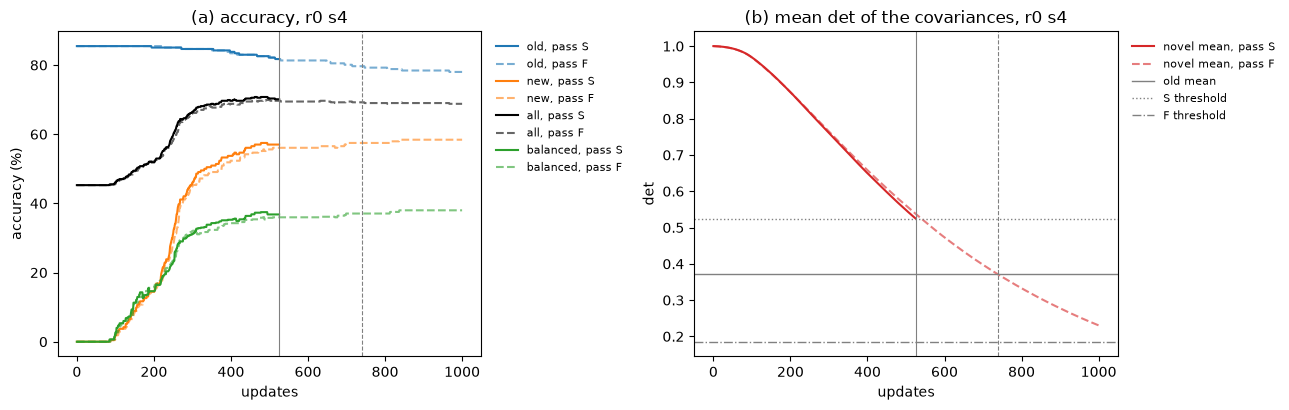

In [5]:
# 3.2 Figure 2 of the paper on GC10 (r0 s4): accuracy on the old test set (241), the novel test set (214, cluster space as
#     step 14), all 455, and balanced novel, along both trajectories, with the pipeline's classifier (_predict, 10 slots);
#     panel (b): mean det of the novel slots against the old det and the S / F thresholds
import jax.numpy as jnp
import matplotlib.pyplot as plt

st = replay.load(RUN, "13", check=False)
replay.predict_default(st["clf"])
P0 = st["params0"]
X = jnp.asarray(np.vstack([st["z_test0"], st["z_test1"]]))
y_old = np.asarray(st["true_test0_y"]).astype(int)
y_new = np.asarray(st["lut"])[np.asarray(st["true_test1_y"]).astype(int)]          # true ids -> cluster space
n_old, y_all = len(y_old), np.concatenate([y_old, y_new])

def acc_curve(T):
    """(steps, 4): old, new, all, balanced novel, in %, for every recorded step of a trajectory."""
    rows = []
    for mu, cov in zip(T["mu"], T["cov"]):
        p = {"class_means": jnp.asarray(np.concatenate([np.asarray(P0["class_means"][:5]), mu])),
             "class_covs": jnp.asarray(np.concatenate([np.asarray(P0["class_covs"][:5]), cov]))}
        pred = np.asarray(st["clf"]._predict(X, p)[0])
        po, pn = pred[:n_old], pred[n_old:]
        bal = np.mean([(pn[y_new == c] == c).mean() for c in np.unique(y_new)])
        rows.append(((po == y_old).mean(), (pn == y_new).mean(), (pred == y_all).mean(), bal))
    return 100 * np.array(rows)

t0 = time.time()
for p in TRAJ:
    TRAJ[p]["acc"] = acc_curve(TRAJ[p])
aF, aS = TRAJ["F"]["acc"], TRAJ["S"]["acc"]
m = json.loads((replay._run_dir(RUN) / "metrics.json").read_text())
print(f"accuracy along both trajectories: {time.time() - t0:.0f} s")
print(f"check, end of pass S: old {aS[-1, 0]:.2f} ({m['S1_Old']:.2f}) | new {aS[-1, 1]:.2f} ({m['S1_New']:.2f}) | all {aS[-1, 2]:.2f} ({m['S1_All']:.2f})")
print(f"check, end of pass F: balanced novel {aF[-1, 3] / 100:.3f} (ledger column 11: 0.380)")
cols = ["old", "new", "all", "balanced"]
for p, a, steps in (("F", aF, (0, 25, 50, 100, 200, 300, 400, 525, 740, 1000)), ("S", aS, (0, 25, 50, 100, 200, 300, 400, 525))):
    print(f"\npass {p}, accuracy (%) at update t:")
    print(pd.DataFrame(a[list(steps)], index=[f"t={t}" for t in steps], columns=cols).round(2).to_string())
    for j, c in ((2, "all"), (3, "balanced")):
        k = int(a[:, j].argmax())
        print(f"  {c} peaks at t={k}: {a[k, j]:.2f}% (old {a[k, 0]:.2f}, new {a[k, 1]:.2f})")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
for j, (c, color) in enumerate(zip(cols, ("tab:blue", "tab:orange", "black", "tab:green"))):
    ax1.plot(aS[:, j], color=color, label=f"{c}, pass S")
    ax1.plot(aF[:, j], color=color, ls="--", alpha=0.6, label=f"{c}, pass F")
ax1.set(xlabel="updates", ylabel="accuracy (%)", title="(a) accuracy, r0 s4")
ax2.plot(TRAJ["S"]["det_mean"], color="tab:red", label="novel mean, pass S")
ax2.plot(TRAJ["F"]["det_mean"], color="tab:red", ls="--", alpha=0.6, label="novel mean, pass F")
for v, name, ls in ((det_old, "old mean", "-"), (det_old / np.sqrt(0.5), "S threshold", ":"), (det_old / 2, "F threshold", "-.")):
    ax2.axhline(v, color="gray", ls=ls, lw=1, label=name)
ax2.set(xlabel="updates", ylabel="det", title="(b) mean det of the covariances, r0 s4")
for ax in (ax1, ax2):
    ax.axvline(525, color="gray", lw=0.8)
    ax.axvline(740, color="gray", lw=0.8, ls="--")
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

- **Kết quả** (r0 s4; tính 1500 lần dự đoán trong 57 s):
  - Phép kiểm đạt:
    - cuối lượt S ra old 81.74, new 57.01, all 70.11, trùng `metrics.json`;
    - cuối lượt F ra balanced 0.380, trùng cột 11.
  - Lớp mới bằng 0% từ bước 0 tới bước 50. Sau đó tăng lên 0.9–1.9% ở bước 100, 14.5% ở bước 200, 45–46% ở bước 300, 52–54% ở bước 400. Cuối lượt S là 57.0%; lượt F lên 58.4% ở bước 1000.
  - Lớp cũ:
    - đứng ở 85.48% tới khoảng bước 200;
    - giảm còn 84.65% ở bước 300, 81.74% ở bước 525;
    - ở lượt F: 79.67% ở bước 740 và 78.01% ở bước 1000.
  - All đạt đỉnh ở bước 462 của lượt S (70.77%) và bước 484 của lượt F (69.89%). Ở bước 525, lượt S là 70.11%; ở bước 740, lượt F là 69.23%.
  - Balanced novel: lượt S đạt đỉnh 37.47% ở bước 478; lượt F tăng chậm tới 38.00% từ bước 837.
  - Ở cùng bước 525 (tự tính từ bảng), lượt S trừ lượt F:
    - old 0.00 (cùng 197/241);
    - new +0.94 (+2 ảnh);
    - balanced +0.83;
    - all +0.44.
  - Lượt F, bước 525 so với bước 1000 (tự tính):
    - old +3.73 (197 so với 188/241, tức giữ thêm 9 ảnh cũ);
    - new −2.34 (−5 ảnh);
    - balanced −2.03;
    - all +0.88.
- **Ý nghĩa**:
  - Đúng ở phép kiểm và ở lớp cũ: 78.01% ở bước 1000 nằm trong khoảng dự đoán 76–80%.
  - Đúng ở ý chính: All không đạt đỉnh ở giao điểm det (bước 740) mà sớm hơn khoảng 260 bước. Câu "giao điểm det là đỉnh của All" (Eq. 9–11) không đứng ở r0 s4.
  - Sai ở hai chỗ:
    - lớp mới không vượt 50% trước bước 100. Nó bằng 0% suốt giai đoạn khởi động (warm-up) và chỉ bắt đầu thắng khe cũ khi đã đi khoảng 30% ngân sách (bước 300);
    - All đạt đỉnh ở bước 462–484, không nằm trong khoảng 100–400.
  - [SUY LUẬN] Khe mới phải tranh ảnh với khe cũ đã có đủ ngân sách. Trong 100 bước khởi động, tổng lr chỉ là 0.0022, tức 6.5% ngân sách, nên số hạng q của khe mới còn quá nhỏ để thắng.
  - Hình dạng các đường giống P1–P3 của paper: lớp cũ giữ nguyên lúc đầu, rồi giảm dần khi lớp mới lên. Nhưng det thì đi xuống chứ không lên như Hình 2b.
  - Ngưỡng S của code (bước 526) rơi rất gần đỉnh All: thấp hơn đỉnh 0.66 điểm, tức khoảng 3 ảnh trên 455. Ngược lại, điểm dừng theo Eq. 11 của paper (bước 734 ở lượt F) thấp hơn đỉnh của lượt F 0.66 điểm và mất thêm 9 ảnh cũ.
  - Phép tách ở r0 s4:
    - **bộ lọc**, ở cùng ngân sách: không đổi lớp cũ, thêm 2 ảnh lớp mới. Dự đoán "giữ thêm 1–5 ảnh cũ" sai;
    - **việc dừng**: giữ 9 ảnh test cũ, đổi lấy 5 ảnh test mới, và 2.0 điểm balanced novel. Đúng khoảng dự đoán (5–15 ảnh cũ; dưới 3 điểm).
    - Đây là đánh đổi ổn định–thích nghi (stability–plasticity) đo trực tiếp: luật dừng mua ổn định bằng một phần khả năng khám phá. Chỉ trên một ảnh chụp, và mỗi ảnh = 0.41 điểm lớp cũ, 0.47 điểm lớp mới.

## 4. Bước dừng qua 15 ảnh chụp

### 4.1 Bước dừng đi theo độ tản của các cụm

Trong một FT seed ngưỡng S gần như cố định (lệch dưới 0.5%, `07` §3.1). Vậy bước dừng phụ thuộc tốc độ rơi của det trung bình, mà det của mỗi khe đi theo độ tản của cụm (`11` §3.1, Spearman +0.89).

**Cách làm**, không dùng nhãn thật, cho mỗi ảnh chụp:
- v_k = phương sai trung bình theo 64 chiều PCA của các ảnh được giữ trong cụm k (đúng dữ liệu mà lượt S học); lấy trung bình và giá trị nhỏ nhất qua 5 cụm;
- det trung bình của khe mới ở `params_f` (2.1);
- det từng khe ở `params1`.

Tính Spearman giữa bước dừng và hai đại lượng trên trong từng FT seed. Mỗi FT seed chỉ có n = 5, nên đây là mô tả.

Đã thấy trước: thứ tự giữa bước dừng và det của lượt F ở 2.1, nên phần det chỉ là phép kiểm nhất quán.

Dự đoán [SUY LUẬN]:
- Spearman(bước dừng, v trung bình) dương ở ít nhất 2/3 FT seed: cụm càng tản thì det càng rơi chậm, nên dừng càng muộn;
- Spearman(bước dừng, det của lượt F) ≥ 0.8 ở cả 3 FT seed;
- ở mọi ảnh chụp, khe có det thấp nhất ở `params1` có v nhỏ nhất (cụm silk chặt).

In [6]:
# 4.1 stop step of pass S over the 15 snapshots against the spread of the clusters it learns (kept pool images, PCA-64,
#     mean within-cluster variance per dimension, as 11 §3.1) and against the mean det of pass F at update 1000;
#     Spearman within each FT seed (n = 5, descriptive); no true labels
from scipy.stats import spearmanr
rows41 = []
for run in RUNS:
    bl = replay.snapshots(run)
    z, ids = np.asarray(bl["05"]["out"]["z_pool"]), np.asarray(bl["09"]["out"]["ids"]).astype(int)
    keep = np.asarray(bl["12"]["out"]["keep"]).astype(bool)
    v = np.array([z[keep & (ids == k)].var(axis=0).mean() for k in range(5)])
    d1 = np.linalg.det(np.asarray(bl["13"]["out"]["params1"]["class_covs"][5:], np.float64))
    tag = run.replace("gc10_v2_ft_", "")
    rows41.append(dict(snap=tag, stop=int(T21.loc[tag, "stop"]), v_mean=round(float(v.mean()), 3), v_min=round(float(v.min()), 3),
                       det_F=round(float(T21.loc[tag, "det_F"]), 4), lowest_det_slot_has_min_v=bool(d1.argmin() == v.argmin()),
                       v_by_cluster=v.round(2).tolist(), det1_by_cluster=d1.round(3).tolist()))
T41 = pd.DataFrame(rows41).set_index("snap")
print(T41.to_string())
for ft in ("r0", "r1", "r2"):
    g = T41[T41.index.str.startswith(ft)]
    print(f"{ft}: Spearman(stop, v_mean) {spearmanr(g['stop'], g['v_mean']).statistic:+.2f} | "
          f"Spearman(stop, v_min) {spearmanr(g['stop'], g['v_min']).statistic:+.2f} | "
          f"Spearman(stop, det_F) {spearmanr(g['stop'], g['det_F']).statistic:+.2f}")
print("lowest-det slot of params1 = cluster with the smallest v in", int(T41["lowest_det_slot_has_min_v"].sum()), "/ 15")

       stop  v_mean  v_min   det_F  lowest_det_slot_has_min_v                                                                                           v_by_cluster                      det1_by_cluster
snap                                                                                                                                                                                                     
r0_s0   619   1.057  0.468  0.2779                       True    [0.4699999988079071, 1.7899999618530273, 0.9399999976158142, 0.9200000166893005, 1.159999966621399]  [0.356, 0.876, 0.509, 0.358, 0.524]
r0_s1   620   1.036  0.467  0.2820                       True    [1.159999966621399, 0.9200000166893005, 0.4699999988079071, 1.7000000476837158, 0.9300000071525574]  [0.521, 0.359, 0.359, 0.881, 0.501]
r0_s2   593   1.032  0.563  0.2631                       True   [0.5600000023841858, 0.9800000190734863, 1.7799999713897705, 0.9300000071525574, 0.9100000262260437]  [0.378, 0.422, 0.912, 0.53

- **Kết quả**:
  - Bước dừng, phương sai trung bình trong cụm (v_mean, tính trên ảnh được giữ) và det trung bình của lượt F ở bước 1000:
    - r0: 619 / 620 / 593 / 531 / 526; v_mean 1.057 / 1.036 / 1.032 / 0.863 / 0.840; det_F 0.278 / 0.282 / 0.263 / 0.225 / 0.230;
    - r1: 543 / 549 / 534 / 486 / 468; v_mean 1.069 / 1.058 / 1.055 / 0.947 / 0.874;
    - r2: 503 / 507 / 493 / 475 / 490; v_mean 1.017 / 0.940 / 0.945 / 0.871 / 0.940.
  - Spearman với bước dừng, trong từng FT seed (r0 / r1 / r2):
    - với v_mean: +0.90 / +0.90 / +0.56;
    - với v_min: +0.60 / +0.10 / +0.87;
    - với det_F: +0.90 / +0.90 / +1.00.
  - Ở `params1`, khe có det thấp nhất là cụm có v nhỏ nhất ở 14/15 ảnh chụp. Ngoại lệ là r2 s0: v nhỏ nhất 0.58 (cụm 2) nhưng det thấp nhất ở cụm 0 (v 0.72; det 0.492 so với 0.496).
  - Cụm chặt nhất (v_min) có v 0.22–0.27 ở các ảnh chụp dừng sớm của r0, r1 (s3, s4) và ở r2 s1–s4, nhưng 0.47–0.58 ở r0 s0–s2, r1 s0–s2 và r2 s0.
- **Ý nghĩa**:
  - Đúng như dự đoán ở cả ba ý:
    - v_mean dương ở cả 3 FT seed;
    - det_F ≥ 0.8 ở cả 3 FT seed (phép kiểm nhất quán, vì thứ tự đã thấy ở 2.1);
    - khe chặt nhất có det thấp nhất ở 14/15.
  - Trong một FT seed, bước dừng của lượt S đi theo độ tản của các cụm mà nó học: cụm càng chặt, det trung bình càng rơi nhanh, luật dừng càng sớm.
  - Ảnh chụp có cụm crease dừng muộn hơn vì cụm silk chặt nhất của chúng tản hơn (0.47–0.56 so với 0.22–0.23), không phải vì bản thân cụm crease.
  - [SUY LUẬN] Phân hoạch ở bước 09 quyết định ngân sách bước của lượt S (48–64%), và qua đó quyết định điểm cân bằng ổn định–thích nghi của 3.2. Một biến thể ở 09 (E09.06, E09.07) sẽ dời luôn điểm dừng. Tiền đăng ký của chúng phải đo cả S1_Old, không chỉ balanced novel. QD25 đã đặt S1_Old làm ràng buộc, nên không cần đổi quyết định.

## Summary (EN)

1. **Step 13 replays bit for bit, and its size is set by the step budget.** `rerun` gives `params1` identical to the snapshot (pass S stops at update 526 at r0 s4); the 5 old slots stay at `params0` (§1.1). Over 15 snapshots pass S uses 48–64% of the summed learning rate, and the largest novel-mean coordinate follows that share to within 1 point; norms of μ and Σ − I are 5–8 points above it. The final mean det always sits just above the S threshold of its FT seed (§2.1). [inference] D23 holds in pass S: the stop rule, not the data, sets how far the novel slots move.
2. **Q07.01: the novel det falls; it does not rise as in Fig. 2b of the paper.** In both passes the mean det of the novel slots falls monotonically from 1, fastest for the tight silk clusters. Pass F crosses the S threshold (0.524) at update 541 and the old det (0.371, the equality the paper's Eq. 9–11 aim at) at update 740 (§3.1).
3. **Figure 2 on GC10 (r0 s4): the code stops near the peak of All, the paper's rule would not.**
   - Novel accuracy is 0% for the first 50–100 updates and rises only after about 30% of the budget.
   - Old accuracy stays at 85.48% until about update 200, then falls to 81.74% at the stop and to 78.01% at update 1000 of pass F.
   - All peaks at updates 462–484, 0.66 points above the value at the code's stop and about 260 updates before det equality.
   - At equal budget the filter changes the old score by 0 images and the novel score by +2. Stopping at 525 instead of 1000 keeps 9 old test images and costs 5 novel ones (balanced novel −2.0 points): a measured stability–plasticity trade-off (§3.2). One snapshot only.
4. **Across the 15 snapshots, the stop step follows the spread of the clusters pass S learns.** Within FT seeds, Spearman between the stop step and the mean within-cluster variance is +0.90 / +0.90 / +0.56, and with the pass-F det +0.90 / +0.90 / +1.00. The lowest-det slot is the tightest cluster in 14/15 (§4.1). [inference] The partition of step 09 sets the pass-S budget and with it the old/new balance, so a step-09 variant (E09.06, E09.07) also moves the stop; S1_Old must be read alongside balanced novel (QD25).